# Perceptron based on Rosenblatt learning algorithm

In [442]:
# imports
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

In [443]:
# Perceptron class
class Perceptron:
    def __init__(self, threshold=0.0, eta0=0.1, random_state=42, save_weight=False):
        self.eta0 = eta0
        self.weights = None
        self.rng = np.random.default_rng(seed=random_state)
        self.save_weight = save_weight

    def fit(self, X, y, epochs = 1):
        weights_history = []
        bias_history = []
        error_history = []

        if self.save_weight == False or (self.weights is None or self.weights.shape[0] != X.shape[1]):
            self.weights = self.rng.standard_normal(size=(X.shape[1], 1))
            self.bias = self.rng.random()

        weights_history.append(self.weights.ravel().copy())
        bias_history.append(self.bias)

        for _ in range(epochs):
            for x_row, y_val in zip(X, y):
                y_pred = self.activate(self.aggregate(x_row))
                error = y_val - y_pred

                self.weights = self.weights + (x_row * self.eta0 * error).reshape(-1, 1)
                self.bias = (self.bias + self.eta0 * error).item()
                weights_history.append(self.weights.ravel().copy())
                bias_history.append(self.bias)
                error_history.append(error)

        return {
            'weights_history': np.array(weights_history),
            'bias_history': np.array(bias_history),
            'error_history': np.array(error_history),
        }

    def predict(self, X):
        y_pred = []
        for i, x_row in enumerate(X):
            weighted_sum = self.aggregate(x_row)
            y_pred.append(self.activate(weighted_sum))

        return np.array(y_pred)

    def aggregate(self, x_row):
        return x_row.dot(self.weights) + self.bias

    def activate(self, weighted_sum):
        return 1 if weighted_sum >= 0 else 0
            

## Test on generated dataset

### Case 1: Non linearly separable classes

In [444]:
# Dataset simulation and visualisation
X, y = make_classification(
    n_samples=100,
    n_features=3,
    n_informative=3,
    n_repeated=0,
    n_redundant=0,
    random_state=42
)

y = y.reshape((y.shape[0], 1))

X_train, X_test, y_train, y_test =  train_test_split(X, y, random_state=42, test_size=0.2)

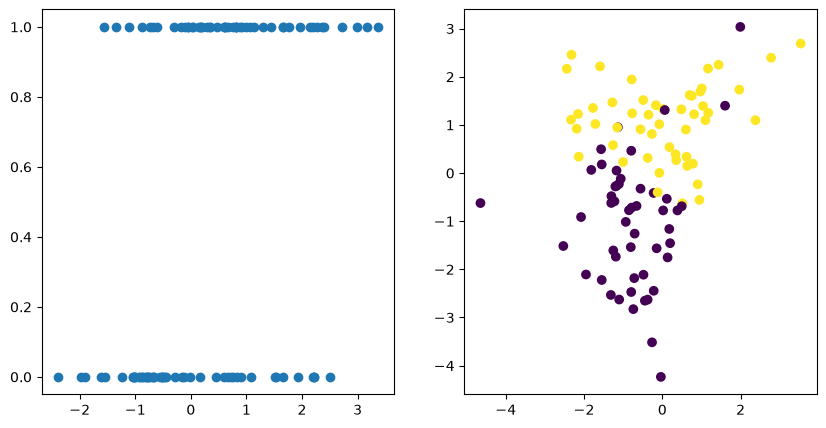

In [445]:
# Visualisation of the dataset
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], y, label='test')
plt.subplot(1, 2, 2)
plt.scatter(X[:, 1], X[:, 2], label='test', c=y)
plt.show()

In [446]:
pct = Perceptron()
history = pct.fit(X_train, y_train, epochs=1)

W = history['weights_history']
B = history['bias_history']
E = history['error_history']

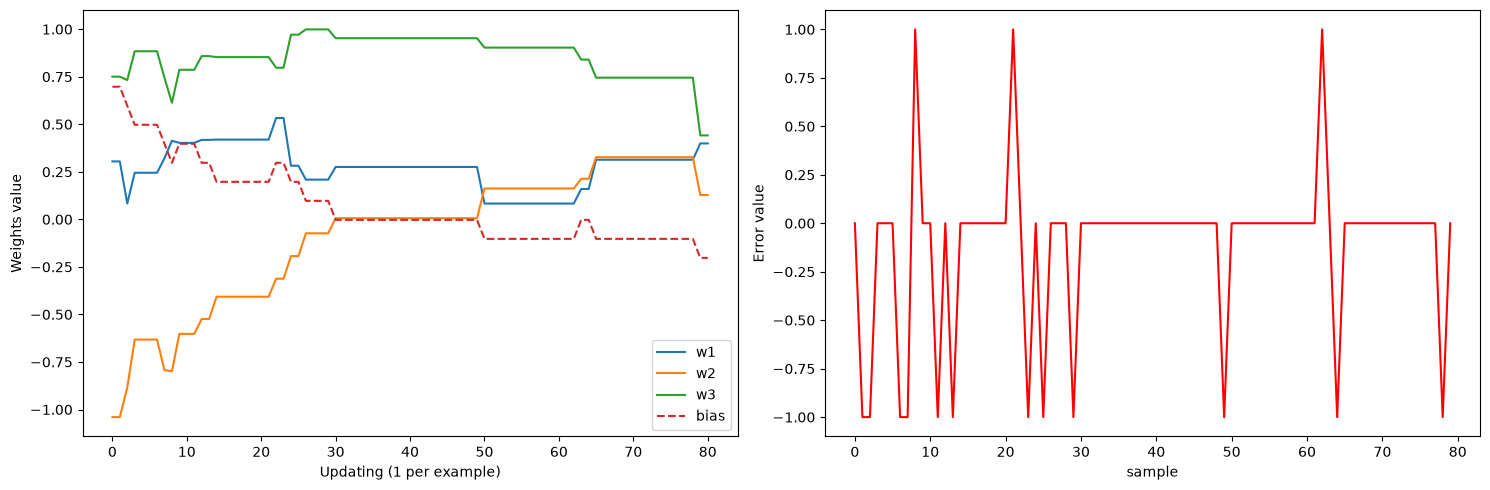

In [447]:
# Evolution of weights, bias and erreur
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(W, label=[f"w{i+1}" for i in range(3)])
plt.plot(B, label='bias', linestyle='--')
plt.xlabel("Updating (1 per example)")
plt.ylabel("Weights value")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(E, c='red')
plt.xlabel("sample")
plt.ylabel("Error value")

plt.tight_layout()
plt.show()

In [448]:
y_train_pred = pct.predict(X_train)
y_test_pred = pct.predict(X_test)

train_accuracy = np.mean(y_train_pred.ravel() == y_train.ravel())
test_accuracy = np.mean(y_test_pred.ravel() == y_test.ravel())

print(f"Accuracy on train : {train_accuracy:.2%}")
print(f"Accuracy on test  : {test_accuracy:.2%}")

Accuracy on train : 82.50%
Accuracy on test  : 100.00%


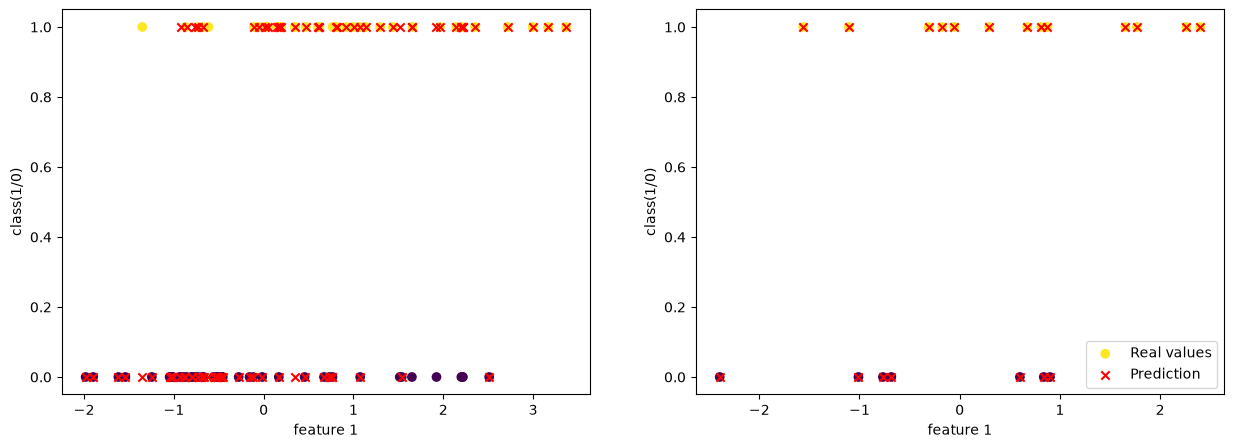

In [449]:
# Comparison of real values and predicted values
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_train[:, 0], y_train, c=y_train, label="Real values")
plt.scatter(X_train[:, 0], y_train_pred, c='red', marker='x', label="Prediction")
plt.xlabel('feature 1')
plt.ylabel('class(1/0)')

plt.subplot(1, 2, 2)
plt.scatter(X_test[:, 0], y_test, c=y_test, label="Real values")
plt.scatter(X_test[:, 0], y_test_pred, c='red', marker='x', label="Prediction")
plt.xlabel('feature 1')
plt.ylabel('class(1/0)')
plt.legend()

plt.show()

### Case 2: linearly separable data

In [450]:
X, y = make_classification(
    n_samples=200,
    n_features=3,
    n_informative=2,
    n_redundant=1,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=1,
    class_sep=3.0,
    flip_y=0.0,
    random_state=42
)

y = y.reshape((y.shape[0], 1))

X_train, X_test, y_train, y_test =  train_test_split(X, y, random_state=42, test_size=0.2)

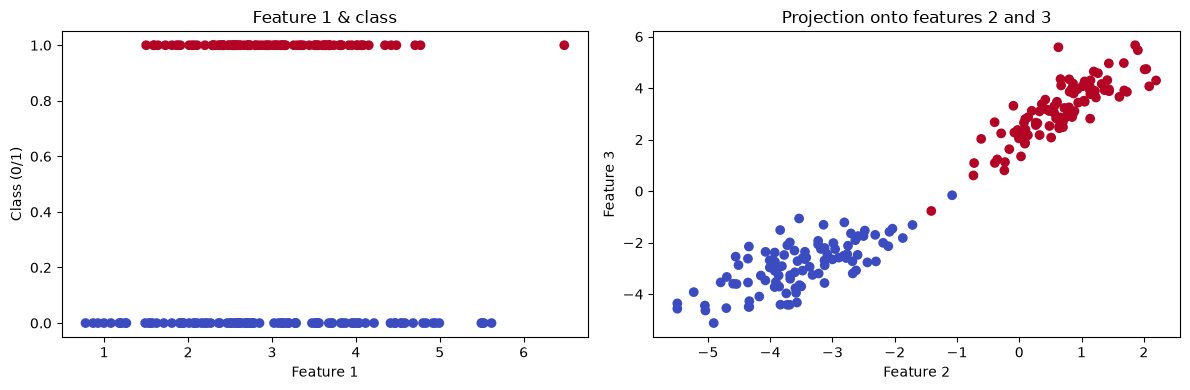

In [451]:
# Visualisation of the dataset
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], y.ravel(), c=y.ravel(), cmap="coolwarm")
plt.xlabel("Feature 1")
plt.ylabel("Class (0/1)")
plt.title("Feature 1 & class")

plt.subplot(1, 2, 2)
plt.scatter(X[:, 1], X[:, 2], c=y.ravel(), cmap="coolwarm")
plt.xlabel("Feature 2")
plt.ylabel("Feature 3")
plt.title("Projection onto features 2 and 3")

plt.tight_layout()
plt.show()

In [452]:
pct = Perceptron(eta0=0.1, random_state=42)
history = pct.fit(X_train, y_train, epochs=1)

W = history["weights_history"]
B = history["bias_history"]
E = history["error_history"]

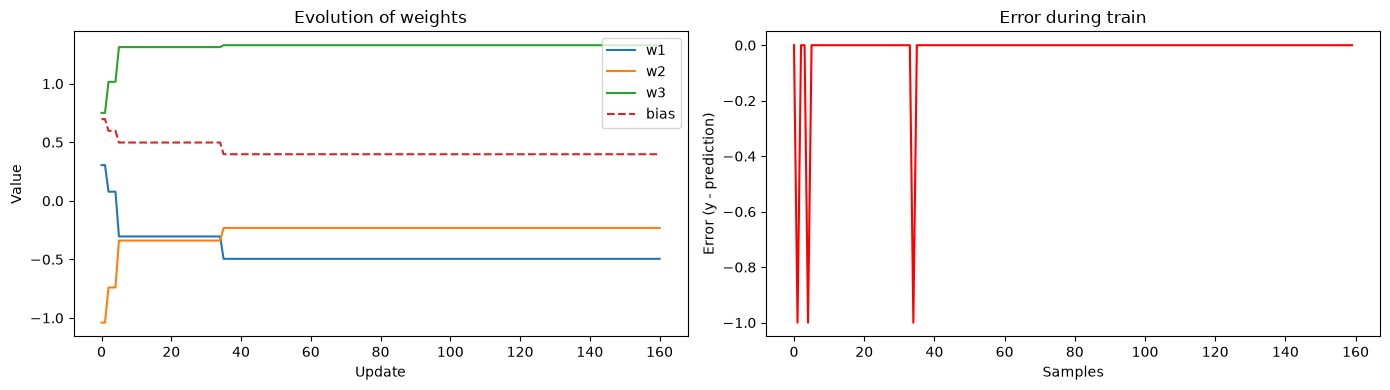

In [453]:
# Evolution of weights, bias and erreur
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.plot(W, label=[f"w{i+1}" for i in range(X_train.shape[1])])
plt.plot(B, label="bias", linestyle="--")
plt.xlabel("Update")
plt.ylabel("Value")
plt.title("Evolution of weights")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(E, color="red")
plt.xlabel("Samples")
plt.ylabel("Error (y - prediction)")
plt.title("Error during train")

plt.tight_layout()
plt.show()

**We can remark here that the with only on epoch, the weights and bias converge, and the error stabilizes. This can, in fact, be considered overfitting.**

In [454]:
# Predictions and evaluation
y_train_pred = pct.predict(X_train)
y_test_pred = pct.predict(X_test)

train_accuracy = np.mean(y_train_pred.ravel() == y_train.ravel())
test_accuracy = np.mean(y_test_pred.ravel() == y_test.ravel())

print(f"Accuracy on train : {train_accuracy:.2%}")
print(f"Accuracy on test  : {test_accuracy:.2%}")

Accuracy on train : 100.00%
Accuracy on test  : 97.50%


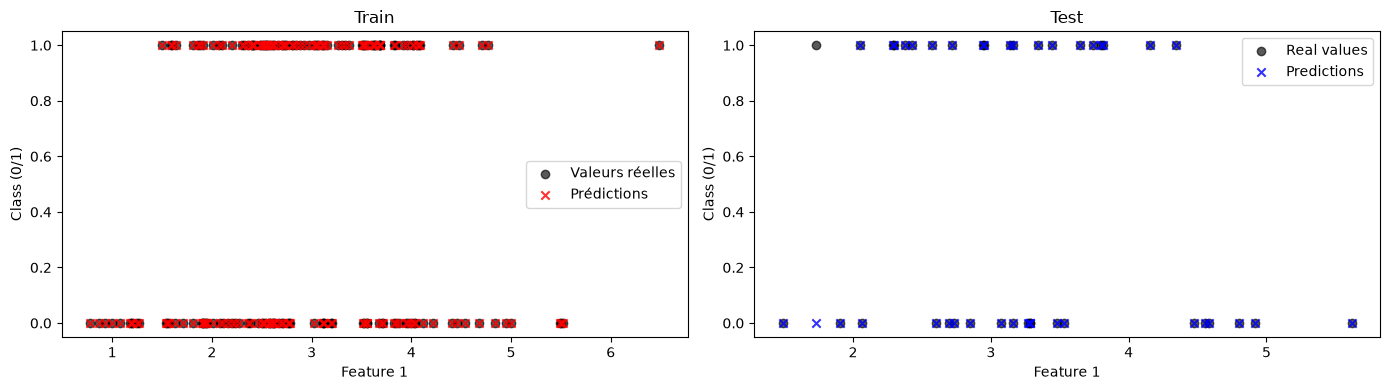

In [455]:
# Comparison of real values and predicted values
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.scatter(X_train[:, 0], y_train.ravel(), c="black", marker="o", label="Valeurs réelles", alpha=0.65)
plt.scatter(X_train[:, 0], y_train_pred.ravel(), c="red", marker="x", label="Prédictions", alpha=0.8)
plt.xlabel("Feature 1")
plt.ylabel("Class (0/1)")
plt.title("Train")
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(X_test[:, 0], y_test.ravel(), c="black", marker="o", label="Real values", alpha=0.65)
plt.scatter(X_test[:, 0], y_test_pred.ravel(), c="blue", marker="x", label="Predictions", alpha=0.8)
plt.xlabel("Feature 1")
plt.ylabel("Class (0/1)")
plt.title("Test")
plt.legend()

plt.tight_layout()
plt.show()